# Financial Transaction Fraud Detector
## Notebook 04a - Model Training

**Owner:** Mahmoud Ibrahim  
**Role:** Model Training (models R/P/L, baselines, thresholds)  
**Course / University:** AI in Cybersecurity, Sohag University  
**Date:** 2026-11-24

**Goal.** Train three models (R, P, L) and two baselines with a time-based split, choose the model for the app, and set its Approve / Review / Block thresholds.

**Inputs:** `data/processed/features.parquet`, `src/train.py`

**Outputs:** `models/model.joblib`, `models/model_meta.json`, `reports/validation.json`, `reports/figures/04a_*.png`

Run the notebooks in order 01, 02, 03, 04a, 04b, 05; each one reads the files saved by the previous one.

## Setup
We read the feature table from notebook 03. Training helpers (split, undersampling, model builders,
threshold search) are in `src/train.py`; every step is called and explained here.

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import data, plotstyle

plotstyle.apply()
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

In [2]:
import joblib
import sklearn
from sklearn.metrics import precision_recall_curve
from sklearn.model_selection import train_test_split

from src import features as F
from src import train as T

feats = data.load_features()
print(f"{len(feats):,} rows, fraud rate {100 * feats['isFraud'].mean():.3f}%")
print(f"scikit-learn version used for training: {sklearn.__version__}")

2,770,409 rows, fraud rate 0.296%
scikit-learn version used for training: 1.9.1


## 1. The three models and two baselines

All three models use the **same algorithm** (`HistGradientBoostingClassifier`, a fast gradient-boosted
decision tree, with `class_weight="balanced"` so the rare fraud class counts as much as the normal class).
They differ **only in what information they get**:

| Model | Features | Meaning |
|---|---|---|
| **R** Realistic | Basic + Receiver history | Only what describes the transaction and the receiver's past. No balances at all. |
| **P** Pre-transaction | R + balances **before** the transaction | What a bank knows at the moment it approves a payment. |
| **L** Leaky | P + balances **after** the transaction and balance errors | Uses information that is distorted by the simulator. **Never used in the app.** |

Baselines: a **Logistic Regression** on the R features (a simple linear model), and the simulator's
**isFlaggedFraud** rule.

In [3]:
for name, cols in F.FEATURE_SETS.items():
    print(f"{name} ({len(cols)}): {', '.join(cols)}")

R (10): is_transfer, amount, log_amount, hour, is_round_amount, is_near_max_amount, recv_count_before, recv_total_before, recv_is_new, recv_hours_since_last
P (13): is_transfer, amount, log_amount, hour, is_round_amount, is_near_max_amount, recv_count_before, recv_total_before, recv_is_new, recv_hours_since_last, oldbalanceOrg, oldbalanceDest, amount_to_balance
L (17): is_transfer, amount, log_amount, hour, is_round_amount, is_near_max_amount, recv_count_before, recv_total_before, recv_is_new, recv_hours_since_last, oldbalanceOrg, oldbalanceDest, amount_to_balance, newbalanceOrig, newbalanceDest, errorOrig, errorDest


## 2. Time-based split

A bank trains on the past and is used on the future. So we sort by `step` (time) and split:
**train** = earliest ~70% of rows, **validation** = next ~15%, **test** = latest ~15%.
The model never sees anything from the validation or test hours while training.

In [4]:
s1, s2 = T.time_split(feats)
train, val, test = T.apply_split(feats, s1, s2)

split_table = pd.DataFrame({
    "steps": [f"1 - {s1 - 1}", f"{s1} - {s2 - 1}", f"{s2} - {feats['step'].max()}"],
    "rows": [len(train), len(val), len(test)],
    "fraud": [int(train["isFraud"].sum()), int(val["isFraud"].sum()), int(test["isFraud"].sum())],
}, index=["train", "validation", "test"])
split_table["fraud_rate_pct"] = 100 * split_table["fraud"] / split_table["rows"]
split_table

,steps,rows,fraud,fraud_rate_pct
train,1 - 322,1938484,3633,0.19
validation,323 - 376,415628,560,0.13
test,377 - 743,416297,4020,0.97


**Note.** The test period has a much higher fraud rate than training and validation. Notebook 02 showed why:
in the last part of the month normal traffic thins out while fraud continues at the same pace. This makes
precision on the test set look **better** than it would be at a normal fraud rate. We therefore also run a
**stratified random split** below as a secondary check.

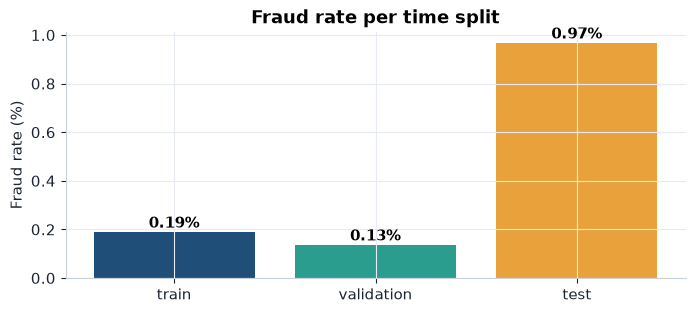

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(split_table.index, split_table["fraud_rate_pct"], color=[plotstyle.NAVY, plotstyle.TEAL, plotstyle.AMBER])
for i, v in enumerate(split_table["fraud_rate_pct"]):
    ax.text(i, v + 0.02, f"{v:.2f}%", ha="center", fontweight="bold")
ax.set_ylabel("Fraud rate (%)")
ax.set_title("Fraud rate per time split")
plotstyle.save(fig, "04a_split_fraud_rate")
plt.show()

## 3. Undersampling the training data only

Normal rows outnumber fraud rows by more than 300 to 1. We keep **every** fraud row in the training set and a
random sample of **50 normal rows per fraud row**. This makes training fast and helps the model focus on fraud.
**Validation and test data are never undersampled**, so all reported numbers reflect the real fraud rate.

In [6]:
train_bal = T.undersample(train, ratio=50)
print(f"Training rows before: {len(train):,} (fraud {int(train['isFraud'].sum()):,})")
print(f"Training rows after undersampling: {len(train_bal):,} (fraud {int(train_bal['isFraud'].sum()):,}, "
      f"rate {100 * train_bal['isFraud'].mean():.2f}%)")

Training rows before: 1,938,484 (fraud 3,633)
Training rows after undersampling: 185,283 (fraud 3,633, rate 1.96%)


## 4. Training

In [7]:
import time

models = {
    "LogReg (R features)": T.make_logreg(F.FEATURE_SETS["R"]),
    "R": T.make_hgb(F.FEATURE_SETS["R"]),
    "P": T.make_hgb(F.FEATURE_SETS["P"]),
    "L": T.make_hgb(F.FEATURE_SETS["L"]),
}
for name, model in models.items():
    start = time.time()
    model.fit(train_bal, train_bal["isFraud"])
    print(f"trained {name:<20} in {time.time() - start:5.1f} s")

trained LogReg (R features)  in   0.4 s


trained R                    in   2.1 s


trained P                    in   2.6 s


trained L                    in   4.2 s


## 5. Validation results

For each model we compute:
- **PR-AUC** (area under the precision-recall curve): the best single number for rare-event problems (1.0 is perfect; a random guess scores about the fraud rate).
- **ROC-AUC**: how well fraud is ranked above normal (can look high even for weak models when fraud is rare).
- **Precision at 85% recall**: if we set the threshold to catch 85% of fraud, what share of the alerts are real fraud?
- **Alerts per 1,000 transactions** at that threshold: the workload for the bank's review team.

In [8]:
val_rows = []
val_scores = {}
recall_thresholds = {}
for name, model in models.items():
    p = model.predict_proba(val)[:, 1]
    val_scores[name] = p
    t = T.threshold_for_recall(val["isFraud"], p, 0.85)
    recall_thresholds[name] = t
    m = T.binary_metrics(val["isFraud"], p >= t)
    val_rows.append({"model": name, **T.score_metrics(val["isFraud"], p),
                     "precision_at_85_recall": m["precision"], "recall": m["recall"],
                     "alerts_per_1000": m["alerts_per_1000"]})
val_table = pd.DataFrame(val_rows).set_index("model")
val_table.style.format("{:.3f}").format("{:.1f}", subset=["alerts_per_1000"])

,roc_auc,pr_auc,precision_at_85_recall,recall,alerts_per_1000
model,,,,,
LogReg (R features),0.850,0.013,0.004,0.850,326.8
R,0.929,0.416,0.010,0.850,116.9
P,1.000,0.913,0.859,0.850,1.3
L,1.000,1.000,1.000,0.991,1.3


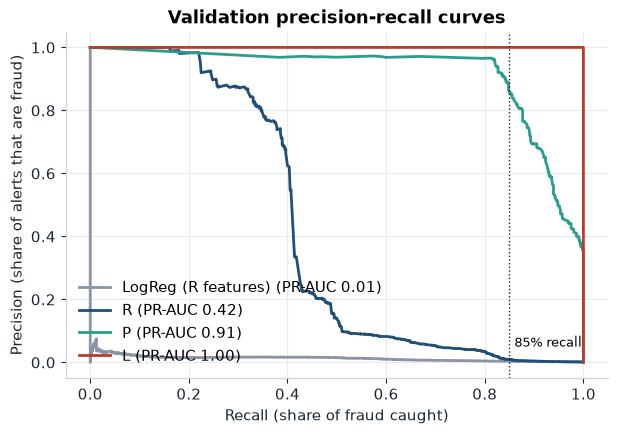

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
colors = {"LogReg (R features)": plotstyle.GREY, "R": plotstyle.NAVY, "P": plotstyle.TEAL, "L": plotstyle.RED}
for name, p in val_scores.items():
    prec, rec, _ = precision_recall_curve(val["isFraud"], p)
    ax.plot(rec, prec, label=f"{name} (PR-AUC {val_table.loc[name, 'pr_auc']:.2f})", color=colors[name], lw=2)
ax.axvline(0.85, color=plotstyle.INK, ls=":", lw=1)
ax.text(0.86, 0.05, "85% recall", fontsize=9)
ax.set_xlabel("Recall (share of fraud caught)")
ax.set_ylabel("Precision (share of alerts that are fraud)")
ax.set_title("Validation precision-recall curves")
ax.legend(loc="lower left")
plotstyle.save(fig, "04a_pr_curves_validation")
plt.show()

## 6. Choosing the model for the app

Our rule, decided **before** looking at the test set:

1. Use **R** if its validation PR-AUC is at least 0.30 **and** it is usable at 85% recall,
   meaning at least 10% of its alerts are real fraud (no more than about 9 false alarms per real fraud).
2. Otherwise use **P** and explain why.
3. **Never** use L.

In [10]:
r = val_table.loc["R"]
r_ok = (r["pr_auc"] >= 0.30) and (r["precision_at_85_recall"] >= 0.10)
primary = "R" if r_ok else "P"
reason = (
    f"R reached PR-AUC {r['pr_auc']:.3f} on validation, but to catch 85% of fraud only "
    f"{100 * r['precision_at_85_recall']:.1f}% of its alerts would be real fraud "
    f"({r['alerts_per_1000']:.0f} alerts per 1,000 transactions), which a bank could not handle. "
    "P adds the balances a bank already knows before approving a payment."
) if not r_ok else "R met both conditions on validation."
print(f"Primary model: {primary}")
print(reason)

Primary model: P
R reached PR-AUC 0.416 on validation, but to catch 85% of fraud only 1.0% of its alerts would be real fraud (117 alerts per 1,000 transactions), which a bank could not handle. P adds the balances a bank already knows before approving a payment.


## 7. Approve / Review / Block thresholds (chosen on validation)

The model outputs a **risk score** between 0 and 1. Two thresholds turn it into a decision:

- score below **t1** -> **Approve**
- score between **t1** and **t2** -> **Review** (a human checks it)
- score at or above **t2** -> **Block**

**t2 (Block)** is the lowest threshold at which at least **90%** of validation alerts are real fraud, so blocking
rarely hurts honest customers.

**t1 (Review)** must catch at least **85%** of validation fraud at "Review or Block". A review costs only a
human check, so we set t1 higher than the minimum: the highest threshold that catches **95%** of validation
fraud. We first check that the extra workload stays small (it is printed below).

In [11]:
p_val = val_scores[primary]
REVIEW_RECALL = 0.95
t1 = T.threshold_for_recall(val["isFraud"], p_val, REVIEW_RECALL)
t2 = T.threshold_for_precision(val["isFraud"], p_val, 0.90)
if t2 is None or t2 <= t1:
    t2 = t1 + (1 - t1) / 2
    print("Note: no threshold reached 90% precision above t1; t2 set halfway between t1 and 1.")

def verdicts(p):
    return np.where(p >= t2, "Block", np.where(p >= t1, "Review", "Approve"))

v = pd.Series(verdicts(p_val), index=val.index)
val_rb = T.binary_metrics(val["isFraud"], v != "Approve")
val_block = T.binary_metrics(val["isFraud"], v == "Block")
print(f"t1 (Review) = {t1:.4f}   t2 (Block) = {t2:.4f}")
print(f"Validation, Review or Block: recall {val_rb['recall']:.3f}, precision {val_rb['precision']:.3f}, "
      f"{val_rb['alerts_per_1000']:.2f} alerts per 1,000")
print(f"Validation, Block only:      recall {val_block['recall']:.3f}, precision {val_block['precision']:.3f}")
pd.crosstab(val["isFraud"].map({0: "Normal", 1: "Fraud"}), v).reindex(columns=["Approve", "Review", "Block"], fill_value=0)

t1 (Review) = 0.9818   t2 (Block) = 0.9945
Validation, Review or Block: recall 0.952, precision 0.496, 2.58 alerts per 1,000
Validation, Block only:      recall 0.841, precision 0.901


col_0,Approve,Review,Block
isFraud,,,
Fraud,27,62,471
Normal,414527,489,52


## 8. Secondary check: stratified random split

Because the time split gives the test period an unusually high fraud rate, we also train R and P on a
**random** 70/15/15 split that keeps the fraud rate equal in every part. If the conclusions agree, they do
not depend on the split.

In [12]:
rtrain, rtemp = train_test_split(feats, test_size=0.30, stratify=feats["isFraud"], random_state=T.RANDOM_STATE)
rval, rtest = train_test_split(rtemp, test_size=0.50, stratify=rtemp["isFraud"], random_state=T.RANDOM_STATE)
rtrain_bal = T.undersample(rtrain, ratio=50)
random_split = {}
for name in ["R", "P"]:
    m = T.make_hgb(F.FEATURE_SETS[name]).fit(rtrain_bal, rtrain_bal["isFraud"])
    pv, pt = m.predict_proba(rval)[:, 1], m.predict_proba(rtest)[:, 1]
    t = T.threshold_for_recall(rval["isFraud"], pv, 0.85)
    bm = T.binary_metrics(rtest["isFraud"], pt >= t)
    random_split[name] = {"test_pr_auc": T.score_metrics(rtest["isFraud"], pt)["pr_auc"],
                          "test_precision_at_val_85_recall": bm["precision"], "test_recall": bm["recall"],
                          "test_alerts_per_1000": bm["alerts_per_1000"]}
print(f"Random split fraud rate (test): {100 * rtest['isFraud'].mean():.3f}%")
pd.DataFrame(random_split).T.style.format("{:.3f}")

Random split fraud rate (test): 0.296%


,test_pr_auc,test_precision_at_val_85_recall,test_recall,test_alerts_per_1000
R,0.449,0.044,0.855,57.813
P,0.949,0.908,0.862,2.813


## 9. Save the model and its description

- `models/model.joblib`: the **primary** pipeline (column selection + trained model). This is the only model the app loads.
- `models/model_meta.json`: features, thresholds, which model, and the scikit-learn version (the app checks it).
- `data/processed/comparison_models.joblib`: all four trained models, for notebook 04b only (not shipped with the app).
- `reports/validation.json`: everything above, for the reports.

In [13]:
data.MODELS.mkdir(exist_ok=True)
joblib.dump(models[primary], data.MODELS / "model.joblib", compress=3)
joblib.dump(models, data.PROCESSED / "comparison_models.joblib", compress=3)

meta = {
    "model": primary,
    "model_name": {"R": "Realistic", "P": "Pre-transaction", "L": "Leaky"}[primary],
    "algorithm": "HistGradientBoostingClassifier(class_weight='balanced')",
    "features": F.FEATURE_SETS[primary],
    "uses_balances": primary != "R",
    "thresholds": {"review": t1, "block": t2},
    "sklearn_version": sklearn.__version__,
    "split_steps": {"train_before": s1, "test_from": s2},
    "selection_reason": reason,
}
data.write_json(meta, data.MODELS / "model_meta.json")

validation = {
    "split": split_table.reset_index(names="part").to_dict(orient="records"),
    "split_steps": {"train_before": s1, "test_from": s2},
    "undersample_ratio": 50,
    "train_rows_after_undersampling": int(len(train_bal)),
    "models": val_table.reset_index().to_dict(orient="records"),
    "thresholds_at_85_recall": recall_thresholds,
    "primary": primary,
    "selection_reason": reason,
    "primary_thresholds": {"review": t1, "block": t2},
    "review_target_recall": REVIEW_RECALL,
    "block_target_precision": 0.90,
    "primary_validation": {"review_or_block": val_rb, "block": val_block},
    "random_split_check": random_split,
}
data.write_json(validation, data.REPORTS / "validation.json")
size_mb = (data.MODELS / "model.joblib").stat().st_size / 1e6
print(f"Saved models/model.joblib ({size_mb:.2f} MB), models/model_meta.json, reports/validation.json")

Saved models/model.joblib (0.10 MB), models/model_meta.json, reports/validation.json


## 10. Check: the saved model loads in a fresh Python process
The app will load the model in a completely new process, so we test exactly that.

In [14]:
import subprocess
import sys

check = f"""
import json, joblib, pandas as pd
from pathlib import Path
root = Path(r"{ROOT}")
model = joblib.load(root / "models" / "model.joblib")
meta = json.loads((root / "models" / "model_meta.json").read_text())
row = pd.read_parquet(root / "data" / "processed" / "features.parquet").head(3)
print("reloaded OK, scores:", [round(float(x), 4) for x in model.predict_proba(row)[:, 1]], "model", meta["model"])
"""
out = subprocess.run([sys.executable, "-c", check], capture_output=True, text=True)
print(out.stdout or out.stderr)
assert out.returncode == 0

reloaded OK, scores: [0.9989, 0.9989, 0.1386] model P



In [15]:
p_row, r_row, l_row = val_table.loc["P"], val_table.loc["R"], val_table.loc["L"]
data.write_findings("04a_model_training", [
    f"Time-based split: train steps 1-{s1 - 1}, validation {s1}-{s2 - 1}, test {s2}-743; the test period has a higher fraud rate ({split_table.loc['test', 'fraud_rate_pct']:.2f}%) because normal traffic thins out late in the month.",
    f"Validation PR-AUC: R {r_row['pr_auc']:.3f}, P {p_row['pr_auc']:.3f}, L {l_row['pr_auc']:.3f}, Logistic Regression {val_table.loc['LogReg (R features)', 'pr_auc']:.3f}.",
    f"Primary model: {primary}. R alone would need {r_row['alerts_per_1000']:.0f} alerts per 1,000 transactions to catch 85% of fraud, with only {100 * r_row['precision_at_85_recall']:.1f}% of alerts being real.",
    f"Thresholds from validation: Review from a score of {t1:.4f}, Block from {t2:.4f}; on validation this catches {100 * val_rb['recall']:.1f}% of fraud at Review or Block ({100 * val_rb['precision']:.1f}% precision, {val_rb['alerts_per_1000']:.1f} alerts per 1,000) and blocks {100 * val_block['recall']:.1f}% with {100 * val_block['precision']:.1f}% precision.",
    f"The stratified random split gives the same picture: test PR-AUC R {random_split['R']['test_pr_auc']:.3f}, P {random_split['P']['test_pr_auc']:.3f}.",
    f"The saved model is {size_mb:.2f} MB and reloads correctly in a fresh process.",
])
print("Findings saved.")

Findings saved.


## Key findings

- Time-based split: train steps 1-322, validation 323-376, test 377-743; the test period has a higher fraud rate (0.97%) because normal traffic thins out late in the month.
- Validation PR-AUC: R 0.416, P 0.913, L 1.000, Logistic Regression 0.013.
- Primary model: P. R alone would need 117 alerts per 1,000 transactions to catch 85% of fraud, with only 1.0% of alerts being real.
- Thresholds from validation: Review from a score of 0.9818, Block from 0.9945; on validation this catches 95.2% of fraud at Review or Block (49.6% precision, 2.6 alerts per 1,000) and blocks 84.1% with 90.1% precision.
- The stratified random split gives the same picture: test PR-AUC R 0.449, P 0.949.
- The saved model is 0.10 MB and reloads correctly in a fresh process.